Write a program to smooth the input image using:
1. Averaging filter (un-weighted)
2. Weighted filter given by h(x,y)= max(|x|.|y|)
3. Gaussian filter
Note: Input the filter size and other parameters such as sigma in case of Gaussian filter,
method of padding (replication, zero padding, etc.) from the user

In [1]:
# ============================================
# IMAGE SMOOTHING USING DIFFERENT FILTERS
# ============================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# --------------------------------------------
# 1. Upload Image
# --------------------------------------------

print("Upload your input image:")
uploaded = files.upload()

filename = next(iter(uploaded))

# Read image
img = cv2.imread(filename)

if img is None:
    print("Error: Image could not be loaded.")
else:
    # Convert BGR to RGB for displaying
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    print("\nImage loaded successfully.")
    print("Image size:", img.shape)

Upload your input image:


Saving Spider Lily.jpeg to Spider Lily.jpeg

Image loaded successfully.
Image size: (1307, 736, 3)


In [2]:
# --------------------------------------------
# 2. Take User Input
# --------------------------------------------

print("\n========== IMAGE SMOOTHING ==========")

print("\nChoose smoothing method:")
print("1. Averaging Filter (Un-weighted)")
print("2. Weighted Filter")
print("3. Gaussian Filter")

choice = int(input("\nEnter your choice (1/2/3): "))

# Filter size
filter_size = int(input("Enter filter size (odd number, e.g. 3, 5, 7): "))

# Check filter size
if filter_size % 2 == 0:
    raise ValueError("Filter size must be an odd number.")



========== IMAGE SMOOTHING ==========

Choose smoothing method:
1. Averaging Filter (Un-weighted)
2. Weighted Filter
3. Gaussian Filter

Enter your choice (1/2/3): 1
Enter filter size (odd number, e.g. 3, 5, 7): 3


In [3]:
# --------------------------------------------
# 3. Padding Selection
# --------------------------------------------

print("\nChoose padding method:")
print("1. Zero Padding")
print("2. Replication")
print("3. Reflection")
print("4. Reflection 101")

padding_choice = int(input("\nEnter padding choice (1-4): "))


# Convert user choice to OpenCV border type
if padding_choice == 1:
    border_type = cv2.BORDER_CONSTANT
elif padding_choice == 2:
    border_type = cv2.BORDER_REPLICATE
elif padding_choice == 3:
    border_type = cv2.BORDER_REFLECT
elif padding_choice == 4:
    border_type = cv2.BORDER_REFLECT_101
else:
    raise ValueError("Invalid padding choice.")




Choose padding method:
1. Zero Padding
2. Replication
3. Reflection
4. Reflection 101

Enter padding choice (1-4): 2



Applying Averaging Filter...


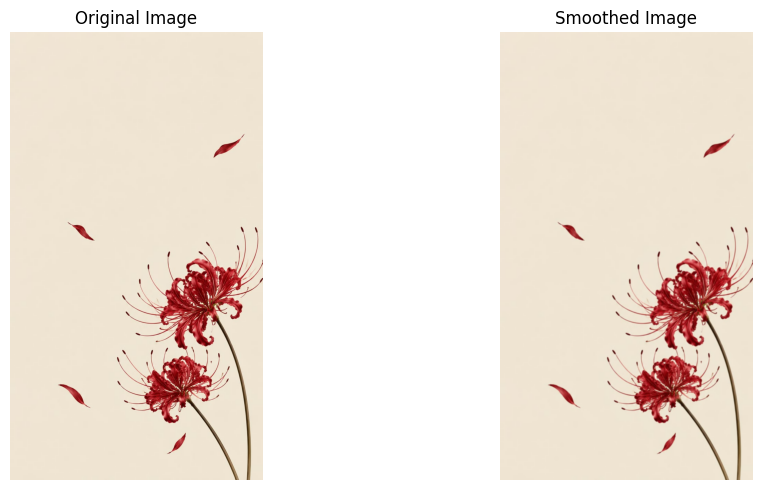


Output saved as: smoothed_image.jpg


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# --------------------------------------------
# 4. Create Filter
# --------------------------------------------

if choice == 1:

    # ----------------------------------------
    # Averaging / Un-weighted Filter
    # ----------------------------------------

    print("\nApplying Averaging Filter...")

    kernel = np.ones(
        (filter_size, filter_size),
        dtype=np.float32
    )

    kernel = kernel / (filter_size * filter_size)

    smoothed = cv2.filter2D(
        img,
        -1,
        kernel,
        borderType=border_type
    )


elif choice == 2:

    # ----------------------------------------
    # Weighted Filter
    # h(x,y) = max(|x|, |y|)
    # ----------------------------------------

    print("\nApplying Weighted Filter...")

    k = filter_size // 2

    kernel = np.zeros(
        (filter_size, filter_size),
        dtype=np.float32
    )

    for i in range(-k, k + 1):
        for j in range(-k, k + 1):

            # h(x,y) = max(|x|, |y|)
            kernel[i + k, j + k] = max(abs(i), abs(j))

    # Center should have maximum contribution.
    # Since h(0,0) = 0, replace zero center with 1
    # to avoid losing the center pixel.
    kernel[k, k] = 1

    # Normalize kernel
    kernel = kernel / np.sum(kernel)

    print("\nWeighted Kernel:")
    print(kernel)

    smoothed = cv2.filter2D(
        img,
        -1,
        kernel,
        borderType=border_type
    )


elif choice == 3:

    # ----------------------------------------
    # Gaussian Filter
    # ----------------------------------------

    sigma = float(input("\nEnter sigma value: "))

    print("\nApplying Gaussian Filter...")

    # Create Gaussian kernel
    kernel_1d = cv2.getGaussianKernel(
        filter_size,
        sigma
    )

    kernel = kernel_1d @ kernel_1d.T

    print("\nGaussian Kernel:")
    print(kernel)

    smoothed = cv2.filter2D(
        img,
        -1,
        kernel,
        borderType=border_type
    )


else:

    raise ValueError("Invalid smoothing method.")


# --------------------------------------------
# 5. Display Results
# --------------------------------------------

smoothed_rgb = cv2.cvtColor(
    smoothed,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(smoothed_rgb)
plt.title("Smoothed Image")
plt.axis("off")

plt.tight_layout()
plt.show()


# --------------------------------------------
# 6. Save Output
# --------------------------------------------

output_filename = "smoothed_image.jpg"

cv2.imwrite(output_filename, smoothed)

print("\nOutput saved as:", output_filename)

# Download output
files.download(output_filename)